In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA


In [2]:
df = pd.read_csv("../dataset/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)

print("\nFirst 5 records:")
print(df.head())


Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

In [3]:
X = df.drop("Heart Disease", axis=1)


In [4]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns


E:\temp\ipykernel_20276\4208230646.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(


In [5]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

X_processed = preprocessor.fit_transform(X)


In [6]:
# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)



Processed Data Shape:
(1000, 27)


In [7]:
pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(X_processed)


In [8]:
pca_df = pd.DataFrame(
    X_pca,
    columns=[
        "Principal Component 1",
        "Principal Component 2"
    ]
)

print("\nPCA Transformed Data:")
print(pca_df.head())



PCA Transformed Data:
   Principal Component 1  Principal Component 2
0               0.014498               0.006885
1               1.327783              -1.536746
2              -0.344586               2.189857
3              -0.724487               0.102921
4              -2.001347              -0.278023


In [9]:
print("\nExplained Variance Ratio:")

print(pca.explained_variance_ratio_)



Explained Variance Ratio:
[0.09800253 0.09356834]


In [10]:
total_variance = pca.explained_variance_ratio_.sum()

print("\nTotal Variance Explained:")
print(total_variance)

print(
    "\nPercentage of Variance Explained:",
    total_variance * 100,
    "%"
)



Total Variance Explained:
0.19157086627338318

Percentage of Variance Explained: 19.15708662733832 %


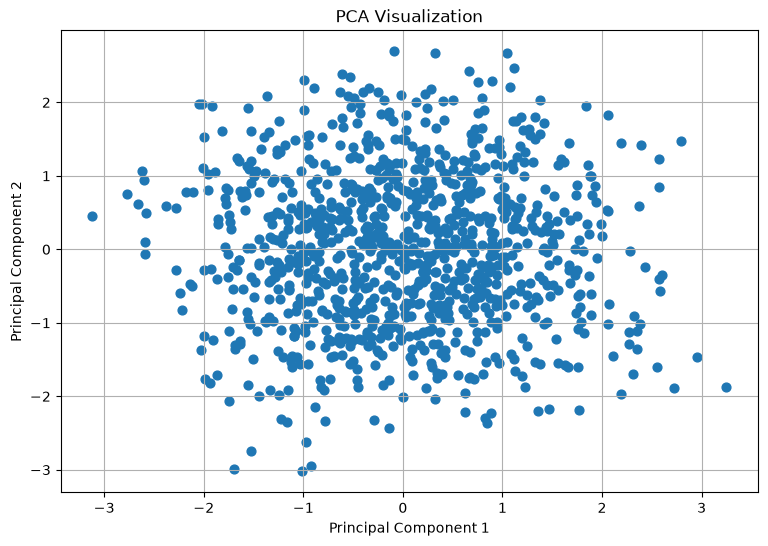

In [11]:
plt.figure(figsize=(9, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Visualization")

plt.grid(True)

plt.show()
